In [1]:
from pathlib import Path
import gzip
import struct
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier



sns.set_theme(style="whitegrid")

# Tìm thư mục khi chạy notebook từ workspace hoặc thư mục bài tập.
assignment_dir = "Ex-03_Nguyen_Hoang_Phuc_CNTT59C"
expected_names = {
    "train-images-idx3-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz",
}
dataset_root = None
for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    candidates = [
        base / assignment_dir / "MNIST_datasets",
        base / assignment_dir / "MNIST_hand_drawn_datasets",
        base / "MNIST_datasets",
        base / "MNIST_hand_drawn_datasets",
        base / "data" / "raw" / "MNIST_hand_drawn",
    ]
    for candidate in candidates:
        if candidate.is_dir() and expected_names.issubset(
            {path.name for path in candidate.rglob("*.gz")}
        ):
            dataset_root = candidate
            break
    if dataset_root is not None:
        break

if dataset_root is None:
    raise FileNotFoundError(
        "Không tìm thấy đủ bốn tệp MNIST IDX .gz. Hãy đặt dữ liệu trong "
        "MNIST_datasets hoặc MNIST_hand_drawn_datasets."
    )

dataset_files = {
    path.name: path for path in dataset_root.rglob("*.gz")
    if path.name in expected_names
}

def load_idx_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"Sai mã IDX ảnh trong {path}: {magic}")
        images = np.frombuffer(file.read(), dtype=np.uint8)
    if images.size != count * rows * cols:
        raise ValueError(f"Kích thước dữ liệu ảnh không hợp lệ: {path}")
    return images.reshape(count, rows, cols)

def load_idx_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        if magic != 2049:
            raise ValueError(f"Sai mã IDX nhãn trong {path}: {magic}")
        labels = np.frombuffer(file.read(), dtype=np.uint8)
    if labels.size != count:
        raise ValueError(f"Số lượng nhãn không khớp: {path}")
    return labels

X_train_raw = load_idx_images(dataset_files["train-images-idx3-ubyte.gz"])
y_train_raw = load_idx_labels(dataset_files["train-labels-idx1-ubyte.gz"])
X_test_raw = load_idx_images(dataset_files["t10k-images-idx3-ubyte.gz"])
y_test_raw = load_idx_labels(dataset_files["t10k-labels-idx1-ubyte.gz"])

print(f"Thư mục dữ liệu: {dataset_root}")
print(f"Train: ảnh {X_train_raw.shape}, nhãn {y_train_raw.shape}")
print(f"Test : ảnh {X_test_raw.shape}, nhãn {y_test_raw.shape}")


Thư mục dữ liệu: /workspaces/LEARNING-ML/Ex-03_Nguyen_Hoang_Phuc_CNTT59C/MNIST_hand_drawn_datasets
Train: ảnh (60000, 28, 28), nhãn (60000,)
Test : ảnh (10000, 28, 28), nhãn (10000,)


,Tập dữ liệu,Số ảnh,Kích thước ảnh,Kiểu pixel,Pixel nhỏ nhất,Pixel lớn nhất,Số nhãn khác nhau
0,Train,60000,28 × 28,uint8,0,255,10
1,Test,10000,28 × 28,uint8,0,255,10


Nhãn trong train: [0 1 2 3 4 5 6 7 8 9]


Giá trị thiếu trong ảnh/nhãn: 0 / 0
Số mẫu train và nhãn không khớp: 0


,Train,Test
Chữ số,,
0,5923,980
1,6742,1135
2,5958,1032
3,6131,1010
4,5842,982
5,5421,892
6,5918,958
7,6265,1028
8,5851,974


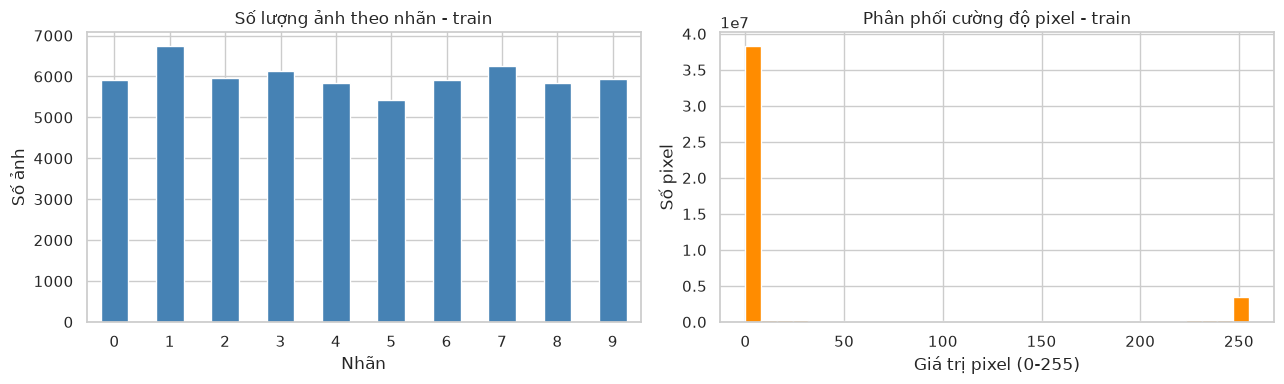

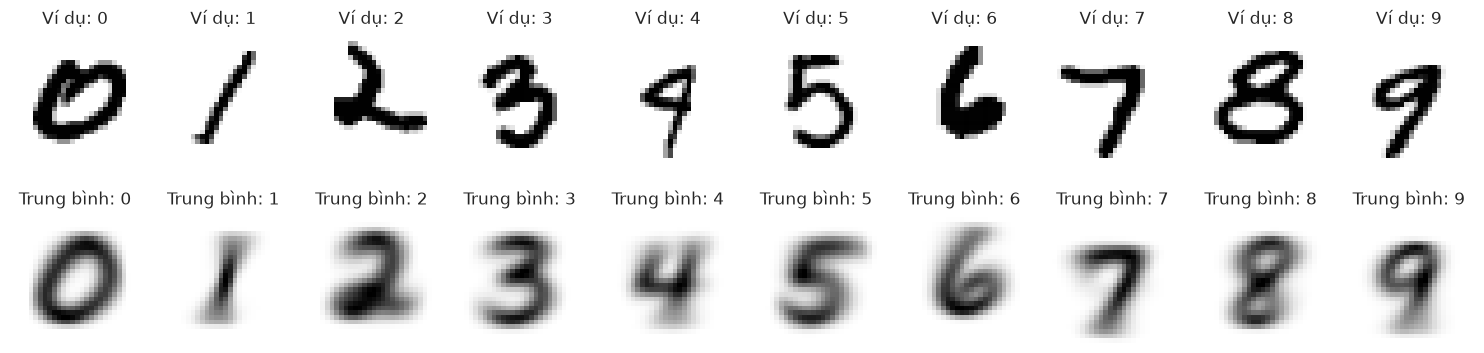

In [2]:
overview = pd.DataFrame([
    {
        "Tập dữ liệu": name,
        "Số ảnh": len(images),
        "Kích thước ảnh": f"{images.shape[1]} × {images.shape[2]}",
        "Kiểu pixel": str(images.dtype),
        "Pixel nhỏ nhất": int(images.min()),
        "Pixel lớn nhất": int(images.max()),
        "Số nhãn khác nhau": np.unique(labels).size,
    }
    for name, images, labels in [
        ("Train", X_train_raw, y_train_raw),
        ("Test", X_test_raw, y_test_raw),
    ]
])
display(overview)
print("Nhãn trong train:", np.unique(y_train_raw))
print("Giá trị thiếu trong ảnh/nhãn:", np.isnan(X_train_raw).sum(), "/", np.isnan(y_train_raw).sum())
print("Số mẫu train và nhãn không khớp:", len(X_train_raw) - len(y_train_raw))

train_counts = pd.Series(y_train_raw).value_counts().sort_index()
test_counts = pd.Series(y_test_raw).value_counts().sort_index()
display(pd.DataFrame({"Train": train_counts, "Test": test_counts}).rename_axis("Chữ số"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_counts.plot(kind="bar", ax=axes[0], color="steelblue", title="Số lượng ảnh theo nhãn - train")
axes[0].set(xlabel="Nhãn", ylabel="Số ảnh")
axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(X_train_raw.ravel(), bins=32, color="darkorange", edgecolor="white")
axes[1].set(title="Phân phối cường độ pixel - train", xlabel="Giá trị pixel (0-255)", ylabel="Số pixel")
plt.tight_layout()
plt.show()

# Mỗi cột là một chữ số: một ảnh ví dụ và ảnh trung bình theo lớp.
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
rng = np.random.default_rng(42)
for digit in range(10):
    example_index = rng.choice(np.flatnonzero(y_train_raw == digit))
    axes[0, digit].imshow(X_train_raw[example_index], cmap="gray_r")
    axes[0, digit].set_title(f"Ví dụ: {digit}")
    axes[1, digit].imshow(X_train_raw[y_train_raw == digit].mean(axis=0), cmap="gray_r")
    axes[1, digit].set_title(f"Trung bình: {digit}")
    axes[0, digit].axis("off")
    axes[1, digit].axis("off")
plt.tight_layout()
plt.show()


In [3]:
TRAIN_SAMPLES = 10_000
TEST_SAMPLES = 2_000
RANDOM_STATE = 42

if TRAIN_SAMPLES > len(X_train_raw) or TEST_SAMPLES > len(X_test_raw):
    raise ValueError("Số mẫu yêu cầu lớn hơn kích thước tập dữ liệu.")

X_train_sample, _, y_train, _ = train_test_split(
    X_train_raw, y_train_raw, train_size=TRAIN_SAMPLES,
    stratify=y_train_raw, random_state=RANDOM_STATE,
)
X_test_sample, _, y_test, _ = train_test_split(
    X_test_raw, y_test_raw, train_size=TEST_SAMPLES,
    stratify=y_test_raw, random_state=RANDOM_STATE,
)
X_train = X_train_sample.reshape(len(X_train_sample), -1).astype(np.float32) / 255.0
X_test = X_test_sample.reshape(len(X_test_sample), -1).astype(np.float32) / 255.0
print(f"Train: {X_train.shape}; test: {X_test.shape}")
print("Tỷ lệ lớp trong train:")
display(pd.Series(y_train).value_counts(normalize=True).sort_index().rename("Tỷ lệ"))

models = {
    "Logistic Regression": LogisticRegression(max_iter=300, tol=1e-3, random_state=RANDOM_STATE),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM (linear)": LinearSVC(C=1.0, dual="auto", max_iter=5_000, random_state=RANDOM_STATE),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(128,), max_iter=30,
        early_stopping=True, random_state=RANDOM_STATE,
    ),
}

results = []
predictions = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    elapsed = time.perf_counter() - start
    predictions[name] = y_pred
    results.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Thời gian (giây)": elapsed,
    })
    print(
        f"{name}: accuracy={results[-1]['Accuracy']:.4f}, "
        f"macro-F1={results[-1]['Macro F1']:.4f}, thời gian={elapsed:.1f}s"
    )

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round({"Accuracy": 4, "Macro F1": 4, "Thời gian (giây)": 1}))


Train: (10000, 784); test: (2000, 784)
Tỷ lệ lớp trong train:


0    0.0987
1    0.1124
2    0.0993
3    0.1022
4    0.0974
5    0.0904
6    0.0986
7    0.1044
8    0.0975
9    0.0991
Name: Tỷ lệ, dtype: float64

Logistic Regression: accuracy=0.9075, macro-F1=0.9059, thời gian=5.1s
Naive Bayes (Gaussian): accuracy=0.5600, macro-F1=0.5046, thời gian=0.1s
k-NN (k=5): accuracy=0.9455, macro-F1=0.9456, thời gian=0.9s
Decision Tree: accuracy=0.8150, macro-F1=0.8113, thời gian=1.8s
SVM (linear): accuracy=0.8940, macro-F1=0.8927, thời gian=2.2s
MLP: accuracy=0.9485, macro-F1=0.9478, thời gian=4.2s


/workspaces/LEARNING-ML/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,Mô hình,Accuracy,Macro F1,Thời gian (giây)
0,MLP,0.9485,0.9478,4.2
1,k-NN (k=5),0.9455,0.9456,0.9
2,Logistic Regression,0.9075,0.9059,5.1
3,SVM (linear),0.8940,0.8927,2.2
4,Decision Tree,0.8150,0.8113,1.8
5,Naive Bayes (Gaussian),0.5600,0.5046,0.1


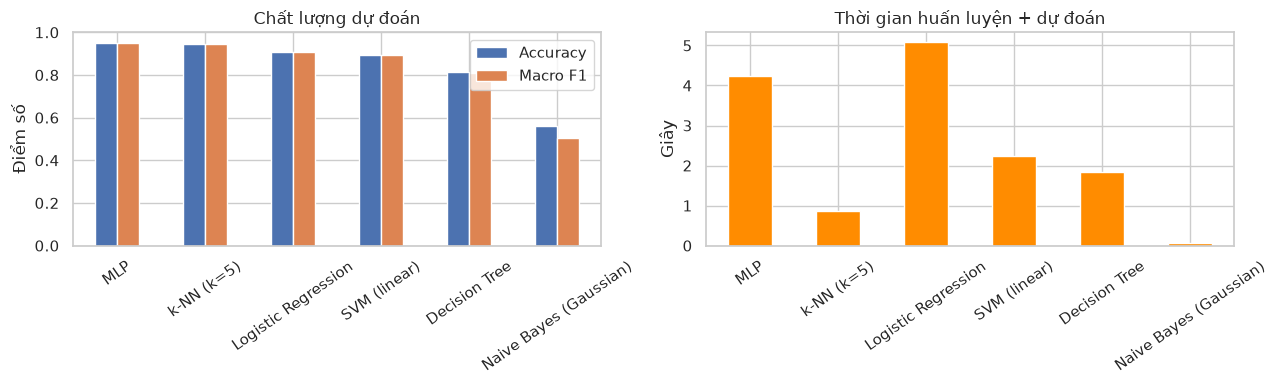

Mô hình có Macro F1 cao nhất: MLP


,Mô hình,Lớp,Precision,Recall,F1-score,Support
0,Logistic Regression,0,0.913,0.969,0.941,196
1,Logistic Regression,1,0.933,0.978,0.955,227
2,Logistic Regression,2,0.910,0.879,0.894,206
3,Logistic Regression,3,0.880,0.906,0.893,202
4,Logistic Regression,4,0.931,0.898,0.914,196
...,...,...,...,...,...,...
67,MLP,7,0.956,0.951,0.954,206
68,MLP,8,0.920,0.944,0.932,195
69,MLP,9,0.935,0.921,0.928,202
70,MLP,macro avg,0.948,0.948,0.948,2000


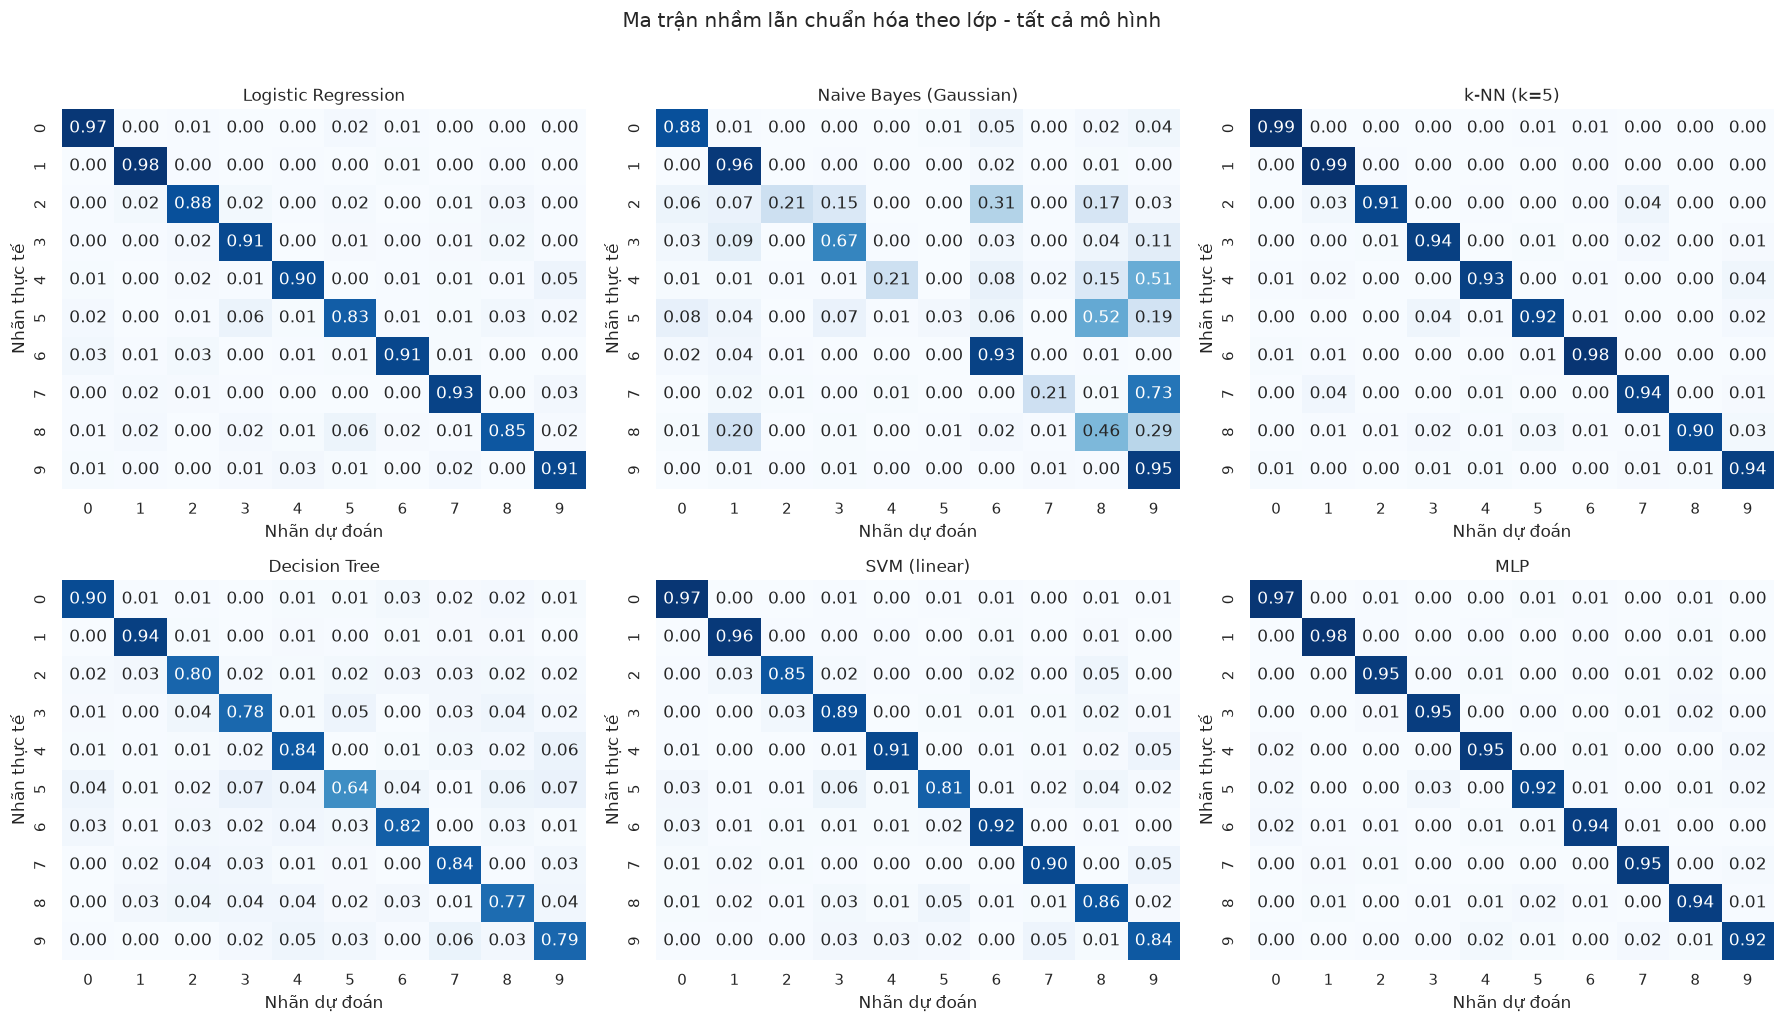

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results_df.plot(x="Mô hình", y=["Accuracy", "Macro F1"], kind="bar", ax=axes[0], ylim=(0, 1), rot=35)
axes[0].set_title("Chất lượng dự đoán")
axes[0].set_ylabel("Điểm số")
axes[0].set_xlabel("")
results_df.plot(x="Mô hình", y="Thời gian (giây)", kind="bar", ax=axes[1], color="darkorange", rot=35, legend=False)
axes[1].set_title("Thời gian huấn luyện + dự đoán")
axes[1].set_ylabel("Giây")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

best_name = results_df.loc[0, "Mô hình"]
print(f"Mô hình có Macro F1 cao nhất: {best_name}")

# Báo cáo precision, recall, F1-score cho từng chữ số và trung bình của mỗi mô hình.
report_rows = []
report_labels = [str(digit) for digit in range(10)] + ["macro avg", "weighted avg"]
for name in models:
    report = classification_report(
        y_test, predictions[name], labels=range(10),
        output_dict=True, zero_division=0,
    )
    for label in report_labels:
        report_rows.append({
            "Mô hình": name,
            "Lớp": label,
            "Precision": report[label]["precision"],
            "Recall": report[label]["recall"],
            "F1-score": report[label]["f1-score"],
            "Support": int(report[label]["support"]),
        })

detailed_report = pd.DataFrame(report_rows)
display(detailed_report.round({"Precision": 3, "Recall": 3, "F1-score": 3}))

# Ma trận nhầm lẫn chuẩn hóa theo nhãn thực tế để so sánh sáu mô hình.
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.flat, models):
    cm = confusion_matrix(y_test, predictions[name], labels=range(10), normalize="true")
    sns.heatmap(
        cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
        cbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")
fig.suptitle("Ma trận nhầm lẫn chuẩn hóa theo lớp - tất cả mô hình", y=1.02)
plt.tight_layout()
plt.show()
